# Notebook 03 — Feature Extraction, Model Training and Evaluation
 

In [1]:

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from nltk.tokenize import word_tokenize
import nltk
import shap
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import VotingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve, auc
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns
nltk.download('punkt', quiet=True)
df = pd.read_csv('../data/preprocessed.csv')


c:\Users\HP\Documents\fake_news_detection\sam312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df['full_text'].value_counts()
df['label'].value_counts()

label
1    21041
0    17901
Name: count, dtype: int64

**Data spliting - Training and Testing**

In [3]:

X = df['full_text']
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f'Train: {len(X_train)} | Test: {len(X_test)}')

Train: 31153 | Test: 7789


In [4]:
len(set(X_train) & set(X_test))  # should now be 0

0

**── TF-IDF ────────────────────────────────────────────────────────────────**
**Term Frequency-Inverse Document Frequency**


In [5]:

tfidf = TfidfVectorizer(
    min_df=5,           
    max_df=0.9,         
    max_features=8000,
    ngram_range=(1, 2), 
    sublinear_tf=True   
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"Vocabulary size : {len(tfidf.vocabulary_)}")
print(f"Train TF-IDF shape: {X_train_tfidf.shape}")
print(f"Test  TF-IDF shape: {X_test_tfidf.shape}")

Vocabulary size : 8000
Train TF-IDF shape: (31153, 8000)
Test  TF-IDF shape: (7789, 8000)


**The next Three Cells is just to Check the Features Extracted**

In [6]:
print(tfidf.get_feature_names_out()[:50])

['abadi' 'abandon' 'abbas' 'abbott' 'abc' 'abc news' 'abdullah' 'abe'
 'abedin' 'abide' 'ability' 'able' 'aboard' 'abolish' 'abortion'
 'abortions' 'abroad' 'abruptly' 'absence' 'absolute' 'absolutely'
 'absurd' 'abu' 'abuse' 'aca' 'academic' 'academy' 'accelerate' 'accept'
 'acceptable' 'acceptance' 'access' 'accident' 'accidentally'
 'accommodate' 'accompany' 'accomplish' 'accomplishments' 'accord'
 'accord new' 'accord poll' 'accord report' 'accord source' 'accord state'
 'account' 'accountability' 'accountable' 'accuracy' 'accurate'
 'accusation']


In [7]:
df_tfidf = pd.DataFrame(X_train_tfidf.toarray(), columns=tfidf.get_feature_names_out())
print(df_tfidf.head())

   abadi  abandon  abbas  abbott  abc  abc news  abdullah  abe  abedin  \
0    0.0      0.0    0.0     0.0  0.0       0.0       0.0  0.0     0.0   
1    0.0      0.0    0.0     0.0  0.0       0.0       0.0  0.0     0.0   
2    0.0      0.0    0.0     0.0  0.0       0.0       0.0  0.0     0.0   
3    0.0      0.0    0.0     0.0  0.0       0.0       0.0  0.0     0.0   
4    0.0      0.0    0.0     0.0  0.0       0.0       0.0  0.0     0.0   

      abide  ...  zarrab  zealand  zero  zika  zika virus  zimbabwe  zinke  \
0  0.000000  ...     0.0      0.0   0.0   0.0         0.0       0.0    0.0   
1  0.000000  ...     0.0      0.0   0.0   0.0         0.0       0.0    0.0   
2  0.000000  ...     0.0      0.0   0.0   0.0         0.0       0.0    0.0   
3  0.000000  ...     0.0      0.0   0.0   0.0         0.0       0.0    0.0   
4  0.042571  ...     0.0      0.0   0.0   0.0         0.0       0.0    0.0   

   zone  zuckerberg  zuma  
0   0.0         0.0   0.0  
1   0.0         0.0   0.0  
2 

In [8]:
row = df_tfidf.iloc[0]
print(row[row > 0])

agencies              0.118564
cite                  0.110078
clarity               0.185789
continue              0.080350
counterpart           0.165018
discussions           0.145350
dmitry                0.183927
dmitry peskov         0.189910
donald                0.053877
donald trump          0.054538
friday                0.140471
friday trump          0.185218
house                 0.064429
house say             0.136263
kremlin               0.256396
kremlin say           0.190581
meet                  0.166597
meet russian          0.304841
moscow                0.122380
moscow reuters        0.152342
news                  0.071506
not                   0.040386
peskov                0.189689
possible              0.167094
president             0.082460
president donald      0.082703
president vladimir    0.140602
putin                 0.125108
quote                 0.129529
reuters               0.047323
russian               0.212313
russian president     0.145693
say     

**Cross-validation on training data And**
**Train SVM model on full training set then evaluate on test**

SVM CV F1 Scores : [0.9953 0.9958 0.9952 0.9958 0.995 ]
SVM CV Mean F1   : 0.9954 (+/- 0.0003)

SVM REPORT
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3580
           1       1.00      1.00      1.00      4209

    accuracy                           1.00      7789
   macro avg       1.00      1.00      1.00      7789
weighted avg       1.00      1.00      1.00      7789



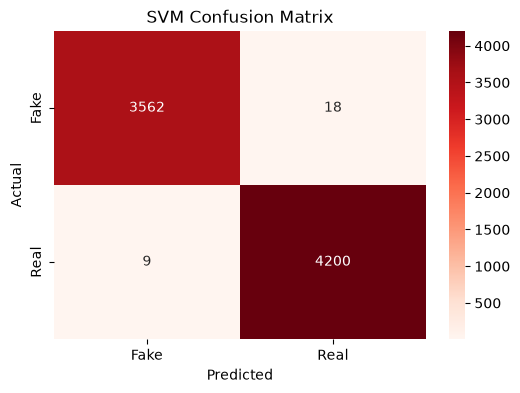

In [9]:

svm_model = LinearSVC(max_iter=1000, random_state=42)

svm_cv_scores = cross_val_score(svm_model, X_train_tfidf, y_train, cv=5, scoring='f1_weighted')
print(f"SVM CV F1 Scores : {svm_cv_scores.round(4)}")
print(f"SVM CV Mean F1   : {svm_cv_scores.mean():.4f} (+/- {svm_cv_scores.std():.4f})")

svm_model.fit(X_train_tfidf, y_train)
svm_predictions = svm_model.predict(X_test_tfidf)

print("\nSVM REPORT")
print(classification_report(y_test, svm_predictions))

plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, svm_predictions),
            annot=True, fmt='d', cmap='Reds',
            xticklabels=['Fake', 'Real'],
            yticklabels=['Fake', 'Real'])
plt.title('SVM Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

**── Naive Bayes Model ───────────────────────────────────────────────────────────────**
**Cross-validation on training data And Train on full training set then evaluate on test**


Naive Bayes CV F1 Scores : [0.9544 0.9525 0.9573 0.9504 0.9528]
Naive Bayes CV Mean F1   : 0.9535 (+/- 0.0023)

NAIVE BAYES REPORT
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      3580
           1       0.95      0.95      0.95      4209

    accuracy                           0.95      7789
   macro avg       0.95      0.95      0.95      7789
weighted avg       0.95      0.95      0.95      7789



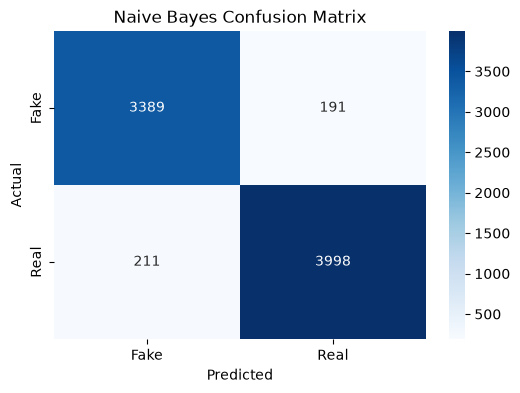

In [10]:

nb_model = MultinomialNB()

nb_cv_scores = cross_val_score(nb_model, X_train_tfidf, y_train, cv=5, scoring='f1_weighted')
print(f"Naive Bayes CV F1 Scores : {nb_cv_scores.round(4)}")
print(f"Naive Bayes CV Mean F1   : {nb_cv_scores.mean():.4f} (+/- {nb_cv_scores.std():.4f})")

nb_model.fit(X_train_tfidf, y_train)
nb_predictions = nb_model.predict(X_test_tfidf)

print("\nNAIVE BAYES REPORT")
print(classification_report(y_test, nb_predictions))

plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, nb_predictions),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Real'],
            yticklabels=['Fake', 'Real'])
plt.title('Naive Bayes Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

**── Random Forest ─────────────────────────────────────────────────────────────**
**Cross-validation on training data And Train on full training set then evaluate on test**

Random Forest CV F1 Scores : [0.9947 0.9966 0.9965 0.997  0.9955]
Random Forest CV Mean F1   : 0.9961 (+/- 0.0008)

RANDOM FOREST REPORT
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      3580
           1       1.00      1.00      1.00      4209

    accuracy                           1.00      7789
   macro avg       1.00      1.00      1.00      7789
weighted avg       1.00      1.00      1.00      7789



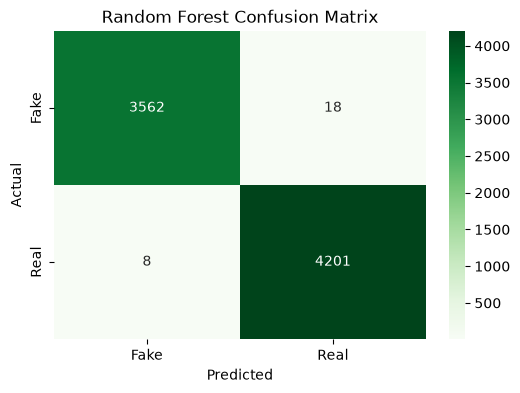

In [11]:

rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

rf_cv_scores = cross_val_score(rf_model, X_train_tfidf, y_train, cv=5, scoring='f1_weighted')
print(f"Random Forest CV F1 Scores : {rf_cv_scores.round(4)}")
print(f"Random Forest CV Mean F1   : {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std():.4f})")

rf_model.fit(X_train_tfidf, y_train)
rf_predictions = rf_model.predict(X_test_tfidf)

print("\nRANDOM FOREST REPORT")
print(classification_report(y_test, rf_predictions))

plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, rf_predictions),
            annot=True, fmt='d', cmap='Greens',
            xticklabels=['Fake', 'Real'],
            yticklabels=['Fake', 'Real'])
plt.title('Random Forest Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

**Check for leakage — are any test samples in training data? And Check what 'full_text' actually contains**

In [12]:

train_set = set(X_train)
test_set  = set(X_test)
overlap   = train_set.intersection(test_set)
print(f"Overlapping samples: {len(overlap)}")

print(df['full_text'].iloc[0])
print(df['label'].value_counts())

Overlapping samples: 0
donald trump send embarrass new year eve message disturb donald trump wish americans happy new year leave instead give shout enemies haters dishonest fake news media former reality show star one job country rapidly grow stronger smarter want wish friends supporters enemies haters even dishonest fake news media happy healthy new year president angry pant tweet great year america country rapidly grow stronger smarter want wish friends supporters enemies haters even dishonest fake news media happy healthy new year great year america donald trump realdonaldtrump december tweet go welll kind president send new year greet like despicable petty infantile gibberish trump lack decency even allow rise gutter long enough wish american citizens happy new year bishop talbert swan talbertswan december one like calvin calvinstowell december impeachment would make great year america also accept regain control congress miranda yaver mirandayaver december hear talk include many pe

**─ Hybrid Voting Ensemble ─────────────────────────────────────────────────────**
**Cross-validation, Train and evaluate**


Ensemble CV F1 Scores : [0.9921 0.9929 0.9929 0.9934 0.9931]
Ensemble CV Mean F1   : 0.9929 (+/- 0.0004)

HYBRID ENSEMBLE REPORT
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      3580
           1       0.99      1.00      0.99      4209

    accuracy                           0.99      7789
   macro avg       0.99      0.99      0.99      7789
weighted avg       0.99      0.99      0.99      7789



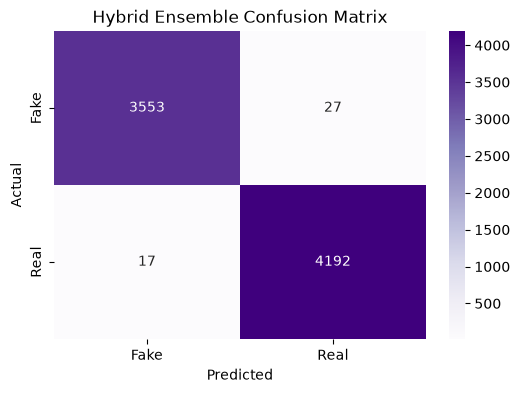

In [13]:

svm_calibrated = CalibratedClassifierCV(LinearSVC(max_iter=1000, random_state=42))

ensemble_model = VotingClassifier(
    estimators=[
        ('svm', svm_calibrated),
        ('nb',  MultinomialNB()),
        ('rf',  RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))
    ],
    voting='soft'
)

ensemble_cv_scores = cross_val_score(ensemble_model, X_train_tfidf, y_train, cv=5, scoring='f1_weighted')
print(f"Ensemble CV F1 Scores : {ensemble_cv_scores.round(4)}")
print(f"Ensemble CV Mean F1   : {ensemble_cv_scores.mean():.4f} (+/- {ensemble_cv_scores.std():.4f})")

ensemble_model.fit(X_train_tfidf, y_train)
ensemble_predictions = ensemble_model.predict(X_test_tfidf)

print("\nHYBRID ENSEMBLE REPORT")
print(classification_report(y_test, ensemble_predictions))

plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, ensemble_predictions),
            annot=True, fmt='d', cmap='Purples',
            xticklabels=['Fake', 'Real'],
            yticklabels=['Fake', 'Real'])
plt.title('Hybrid Ensemble Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Plot ROC curves \
**SVM needs calibration for predict_proba - Get probabilities for class 1 (Real).**

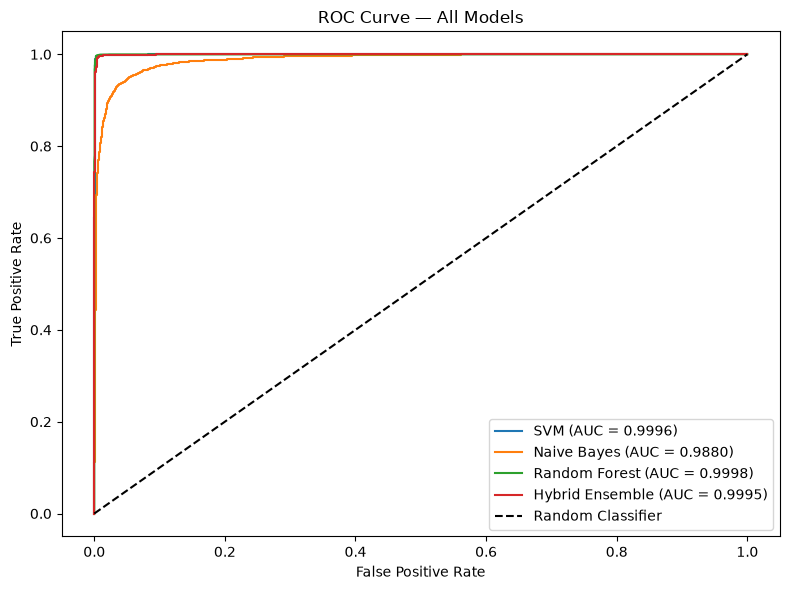

In [14]:

svm_calibrated = CalibratedClassifierCV(LinearSVC(max_iter=1000, random_state=42))
svm_calibrated.fit(X_train_tfidf, y_train)

svm_proba      = svm_calibrated.predict_proba(X_test_tfidf)[:, 1]
nb_proba       = nb_model.predict_proba(X_test_tfidf)[:, 1]
rf_proba       = rf_model.predict_proba(X_test_tfidf)[:, 1]
ensemble_proba = ensemble_model.predict_proba(X_test_tfidf)[:, 1]

plt.figure(figsize=(8, 6))

for name, proba in [('SVM',            svm_proba),
                     ('Naive Bayes',    nb_proba),
                     ('Random Forest',  rf_proba),
                     ('Hybrid Ensemble',ensemble_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_score   = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0,1], [0,1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — All Models')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**── Top features from Random Forest ───────────────────────────────────────────**\
**── Top features from SVM (coefficients) ──────────────────────────────────────**

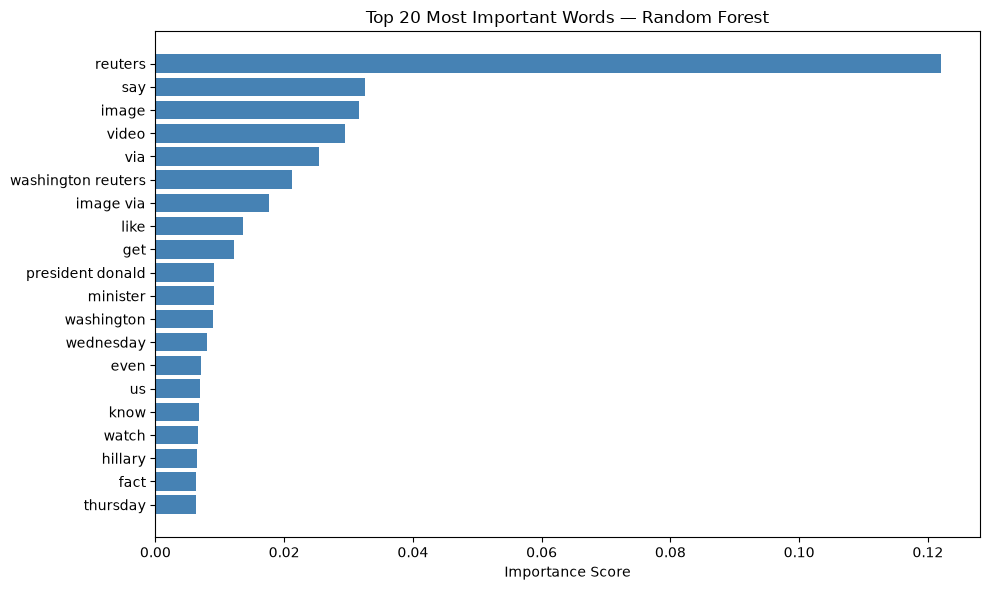

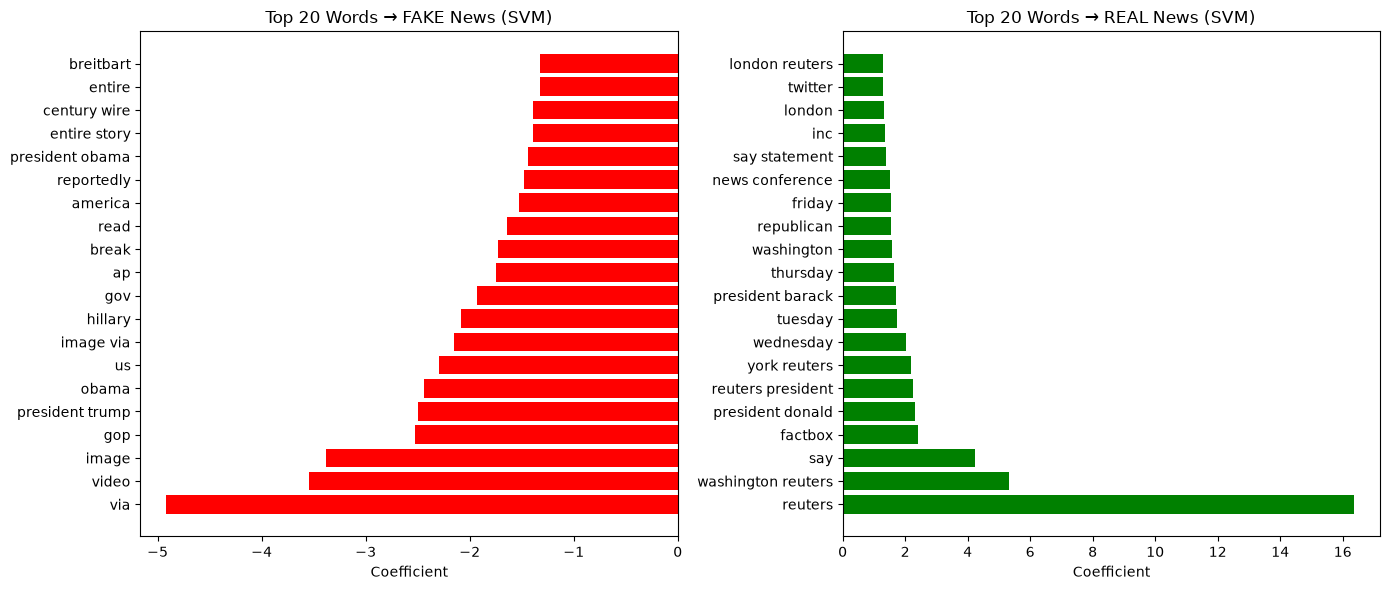

In [15]:
feature_names = np.array(tfidf.get_feature_names_out())

importances = rf_model.feature_importances_
top_indices = np.argsort(importances)[::-1][:20]

plt.figure(figsize=(10, 6))
plt.barh(feature_names[top_indices][::-1], importances[top_indices][::-1], color='steelblue')
plt.xlabel('Importance Score')
plt.title('Top 20 Most Important Words — Random Forest')
plt.tight_layout()
plt.show()

svm_coef = svm_model.coef_[0]
top_fake  = np.argsort(svm_coef)[:20]      
top_real  = np.argsort(svm_coef)[::-1][:20]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(feature_names[top_fake], svm_coef[top_fake], color='red')
axes[0].set_title('Top 20 Words → FAKE News (SVM)')
axes[0].set_xlabel('Coefficient')

axes[1].barh(feature_names[top_real], svm_coef[top_real], color='green')
axes[1].set_title('Top 20 Words → REAL News (SVM)')
axes[1].set_xlabel('Coefficient')

plt.tight_layout()
plt.show()

**── Bar Plot — overall most important features ─────────────────────────────────**\
**── Dot Plot — shows direction of impact ──────────────────────────────────────**

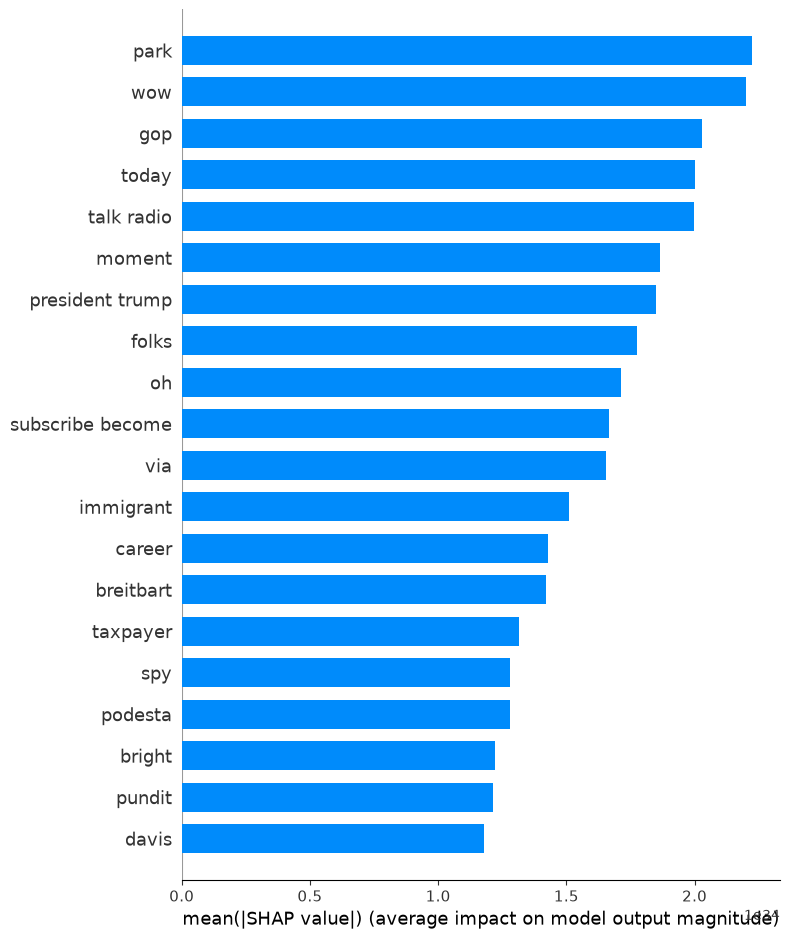

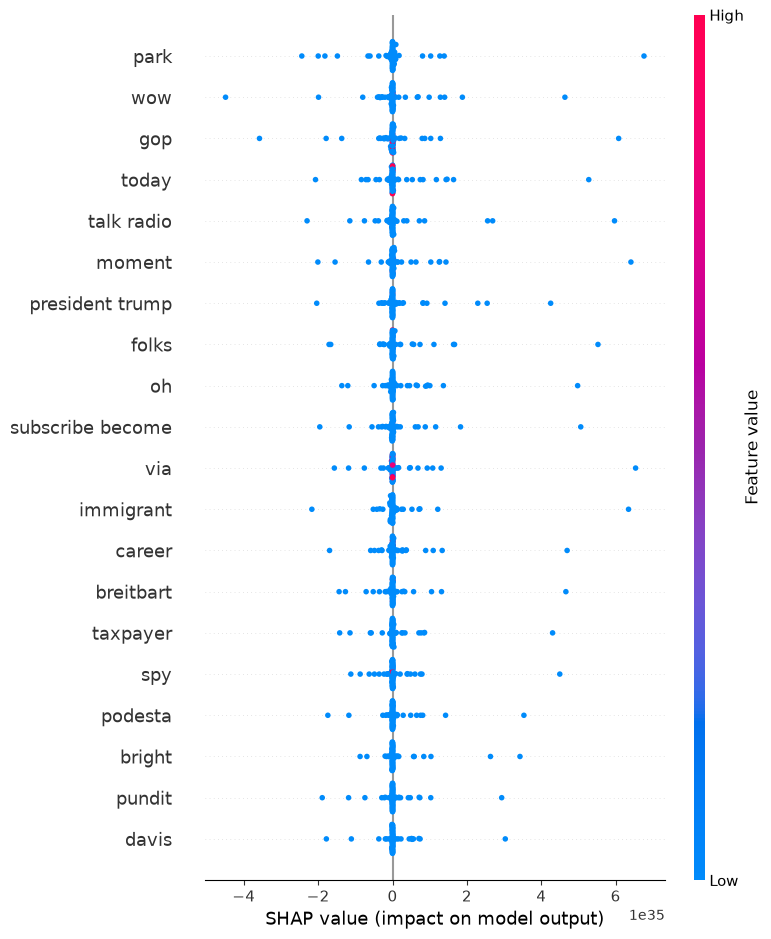

In [16]:
X_test_dense  = X_test_tfidf.toarray()

explainer   = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_dense[:100], check_additivity=False)

shap.summary_plot(
    shap_values[:, :, 1],
    X_test_dense[:100],
    feature_names=tfidf.get_feature_names_out(),
    max_display=20,
    plot_type='bar'
)
shap.summary_plot(
    shap_values[:, :, 1],
    X_test_dense[:100],
    feature_names=tfidf.get_feature_names_out(),
    max_display=20
)

**─ Model Comparison Bar Chart ─────────────────────────────────────────────────**

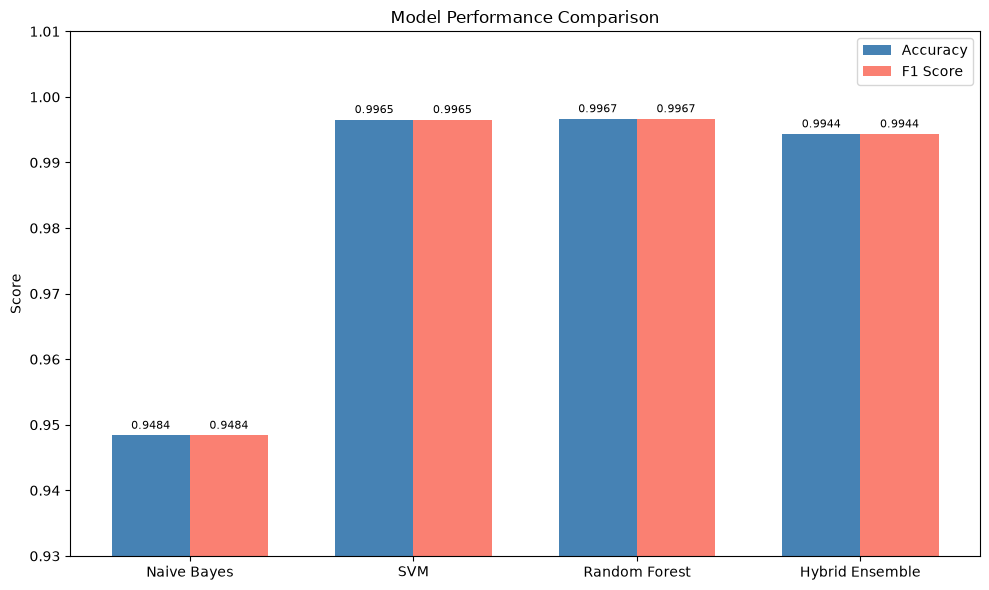

In [17]:
from sklearn.metrics import accuracy_score, f1_score

models      = ['Naive Bayes', 'SVM', 'Random Forest', 'Hybrid Ensemble']
predictions = [nb_predictions, svm_predictions, rf_predictions, ensemble_predictions]

accuracies = [accuracy_score(y_test, p) for p in predictions]
f1_scores  = [f1_score(y_test, p, average='weighted') for p in predictions]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, accuracies, width, label='Accuracy', color='steelblue')
ax.bar(x + width/2, f1_scores,  width, label='F1 Score',  color='salmon')

ax.set_ylim(0.93, 1.01)
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.legend()

for i, (acc, f1) in enumerate(zip(accuracies, f1_scores)):
    ax.text(i - width/2, acc + 0.001, f'{acc:.4f}', ha='center', fontsize=8)
    ax.text(i + width/2, f1  + 0.001, f'{f1:.4f}',  ha='center', fontsize=8)

plt.tight_layout()
plt.show()

**Load the preprocessed LIAR test dataset**\
**Use same TF-IDF fitted on ISOT — do NOT refit with Liar test dataset,  We are just using the Dataset for testing**

statement: 1002 | label: 1002

── Naive Bayes on LIAR ──
              precision    recall  f1-score   support

           0       0.56      0.49      0.52       553
           1       0.45      0.52      0.48       449

    accuracy                           0.50      1002
   macro avg       0.51      0.51      0.50      1002
weighted avg       0.51      0.50      0.51      1002



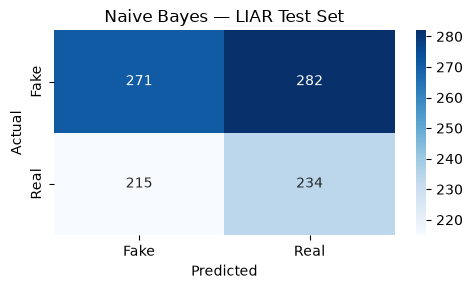


── SVM on LIAR ──
              precision    recall  f1-score   support

           0       0.55      0.92      0.69       553
           1       0.39      0.06      0.11       449

    accuracy                           0.54      1002
   macro avg       0.47      0.49      0.40      1002
weighted avg       0.48      0.54      0.43      1002



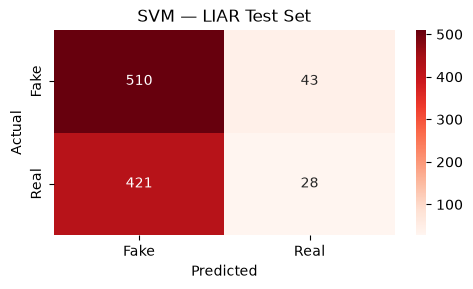


── Random Forest on LIAR ──
              precision    recall  f1-score   support

           0       0.55      1.00      0.71       553
           1       0.00      0.00      0.00       449

    accuracy                           0.55      1002
   macro avg       0.28      0.50      0.36      1002
weighted avg       0.30      0.55      0.39      1002



c:\Users\HP\Documents\fake_news_detection\sam312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\Documents\fake_news_detection\sam312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\HP\Documents\fake_news_detection\sam312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"

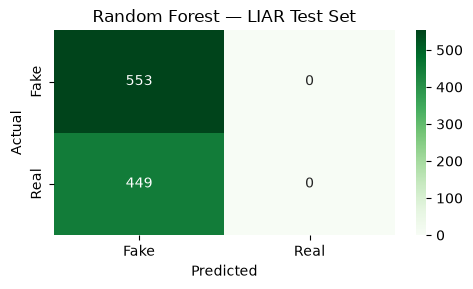


── Hybrid Ensemble on LIAR ──
              precision    recall  f1-score   support

           0       0.55      0.94      0.69       553
           1       0.35      0.04      0.07       449

    accuracy                           0.54      1002
   macro avg       0.45      0.49      0.38      1002
weighted avg       0.46      0.54      0.41      1002



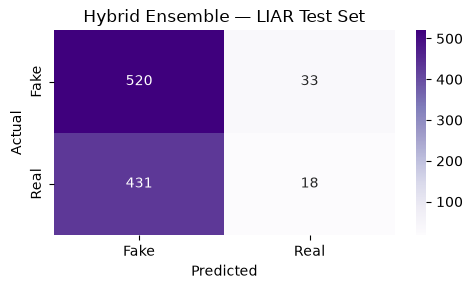

In [18]:

dr= pd.read_csv('../data/liar_test_preprocessed.csv')

X = dr['clean_statement']
y = dr['binary_label']

print(f'statement: {len(X)} | label: {len(y)}')

X_liar_tfidf = tfidf.transform(X)

for name, model, color in [
    ('Naive Bayes',     nb_model,       'Blues'),
    ('SVM',             svm_model,      'Reds'),
    ('Random Forest',   rf_model,       'Greens'),
    ('Hybrid Ensemble', ensemble_model, 'Purples')
]:
    preds = model.predict(X_liar_tfidf)
    print(f"\n── {name} on LIAR ──")
    print(classification_report(y, preds))

    plt.figure(figsize=(5, 3))
    sns.heatmap(confusion_matrix(y, preds),
                annot=True, fmt='d', cmap=color,
                xticklabels=['Fake', 'Real'],
                yticklabels=['Fake', 'Real'])
    plt.title(f'{name} — LIAR Test Set')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

**ISOT vs LIAR - Generalisation Comparison**

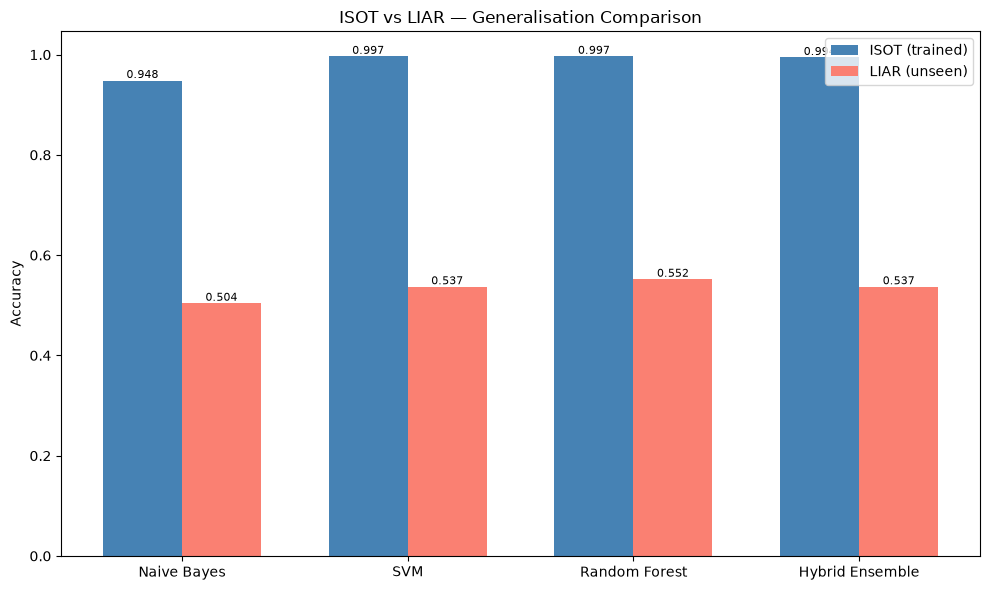

In [19]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

models = ['Naive Bayes', 'SVM', 'Random Forest', 'Hybrid Ensemble']
model_list = [nb_model, svm_model, rf_model, ensemble_model]

isot_accs = [accuracy_score(y_test,  m.predict(X_test_tfidf))  for m in model_list]
liar_accs = [accuracy_score(y,  m.predict(X_liar_tfidf))  for m in model_list]

x     = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, isot_accs, width, label='ISOT (trained)', color='steelblue')
ax.bar(x + width/2, liar_accs, width, label='LIAR (unseen)',  color='salmon')

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel('Accuracy')
ax.set_title('ISOT vs LIAR — Generalisation Comparison')
ax.legend()

for i, (a, b) in enumerate(zip(isot_accs, liar_accs)):
    ax.text(i - width/2, a + 0.005, f'{a:.3f}', ha='center', fontsize=8)
    ax.text(i + width/2, b + 0.005, f'{b:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

In [20]:
import joblib, os
os.makedirs('models', exist_ok=True)

joblib.dump(tfidf,          'models/tfidf_vectorizer.pkl')
joblib.dump(nb_model,       'models/naive_bayes.pkl')
joblib.dump(svm_model,      'models/svm.pkl')
joblib.dump(rf_model,       'models/random_forest.pkl')
joblib.dump(ensemble_model, 'models/hybrid_ensemble.pkl')
print("Models saved ✔")

Models saved ✔
